# ASL Recognition Using YOLOv26

**Module:** Applied AI  
**Project Title:** Real-Time ASL Alphabet Recognition Using YOLOv26  
**Students:** Abdelalime Lahbib and Yasser Karouti  
**Instructor:** Ibtissam Abnane and Brahim Ait Skourt  

---

## Project Overview
This project aims to build an Artificial Intelligence system capable of recognizing American Sign Language (ASL) alphabet signs from images using the YOLOv26 object detection model. The goal is to train and evaluate a detection model that can localize the hand sign and classify it into the correct ASL letter.

This notebook is organized to follow the same structure as the final report:
1. Introduction & Context  
2. Dataset & Representation  
3. Experimental Design  
4. Results & Visual Analysis  
5. Discussion and Conclusion

# 1. Introduction & Context

## 1.1 Background
American Sign Language (ASL) is an important communication system used by deaf and hard-of-hearing communities. Automatic ASL recognition can improve accessibility and support human-computer interaction systems.

## 1.2 Problem Statement
The objective of this project is to train a computer vision model that can detect and classify ASL hand signs from images. The model should identify the location of the hand and assign the corresponding ASL alphabet class.

## 1.3 Why This Project
This project is a good Applied AI problem because it combines:
- computer vision,
- supervised learning,
- object detection,
- model evaluation,
- practical deployment considerations.

## 1.4 Scope
In this project, we focus on:
- static ASL alphabet signs,
- image-based object detection,
- training and testing with a Roboflow dataset,
- evaluation using standard detection metrics.

## 1.5 Main Challenges
Potential challenges include:
- visually similar signs,
- variations in lighting and background,
- class imbalance,
- annotation noise,
- generalization to unseen images.

In [2]:
# =========================================================
# 2. ENVIRONMENT SETUP
# =========================================================

!nvidia-smi
!pip install -q roboflow ultralytics pyyaml matplotlib seaborn opencv-python

Mon Apr  6 11:49:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.105.08             Driver Version: 580.105.08     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
# =========================================================
# 3. IMPORT LIBRARIES
# =========================================================

import os
import yaml
import random
import shutil
from glob import glob
from collections import Counter

import cv2
import numpy as np
import matplotlib.pyplot as plt

from roboflow import Roboflow
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


# 2. Dataset & Representation

## 2.1 Dataset Source
The dataset used in this project was obtained from Roboflow.

**Roboflow Workspace:** `lsmdetection`  
**Project Name:** `asl-alphabet-fb7de`  
**Version:** `2`  
**Format:** `YOLO26`

## 2.2 Expected Dataset Content
The dataset contains labeled images of ASL hand signs. Each image includes annotations in object detection format, where each label contains:
- class index,
- bounding box center coordinates,
- bounding box width,
- bounding box height.

## 2.3 Goals of Dataset Analysis
Before training, we need to verify:
- class names,
- number of classes,
- train/validation/test split,
- annotation correctness,
- sample diversity,
- possible limitations.

In [3]:
# =========================================================
# 4. DOWNLOAD DATASET FROM ROBOFLOW
# =========================================================

rf = Roboflow(api_key="YOUR_ROBOFLOW_API_KEY")
project = rf.workspace("lsmdetection").project("asl-alphabet-fb7de")
version = project.version(2)
dataset = version.download("yolo26")

print("Dataset location:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to asl-alphabet-2 in yolo26:: 100%|██████████| 20012/20012 [00:01<00:00, 10286.58it/s]

Dataset location: /kaggle/working/asl-alphabet-2


In [4]:
# =========================================================
# 5. LOAD DATA CONFIG
# =========================================================

data_yaml_path = os.path.join(dataset.location, "data.yaml")

with open(data_yaml_path, "r") as f:
    data_config = yaml.safe_load(f)

data_config

{'train': '../train/images',
 'val': '../valid/images',
 'test': '../test/images',
 'nc': 27,
 'names': ['A',
  'B',
  'C',
  'D',
  'E',
  'F',
  'G',
  'H',
  'I',
  'J',
  'K',
  'L',
  'M',
  'N',
  'O',
  'P',
  'Q',
  'R',
  'S',
  'T',
  'U',
  'V',
  'W',
  'X',
  'Y',
  'Z',
  'nothing'],
 'roboflow': {'workspace': 'lsmdetection',
  'project': 'asl-alphabet-fb7de',
  'version': 2,
  'license': 'CC BY 4.0',
  'url': 'https://universe.roboflow.com/lsmdetection/asl-alphabet-fb7de/dataset/2'}}

In [5]:
# =========================================================
# 6. EXTRACT BASIC DATASET INFORMATION
# =========================================================

class_names = data_config.get("names", [])
num_classes = len(class_names)

dataset_root = dataset.location
train_dir = os.path.join(dataset_root, "train", "images")
val_dir = os.path.join(dataset_root, "valid", "images")
test_dir = os.path.join(dataset_root, "test", "images")

print("Dataset root:", dataset_root)
print("Number of classes:", num_classes)
print("Class names:", class_names)
print("Train dir:", train_dir, os.path.exists(train_dir))
print("Validation dir:", val_dir, os.path.exists(val_dir))
print("Test dir:", test_dir, os.path.exists(test_dir))

Dataset root: /kaggle/working/asl-alphabet-2
Number of classes: 27
Class names: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'nothing']
Train dir: /kaggle/working/asl-alphabet-2/train/images True
Validation dir: /kaggle/working/asl-alphabet-2/valid/images True
Test dir: /kaggle/working/asl-alphabet-2/test/images True


In [6]:
# =========================================================
# 7. COUNT IMAGES IN EACH SPLIT
# =========================================================

def count_images(images_dir):
    if images_dir is None or not os.path.exists(images_dir):
        return 0
    exts = ["*.jpg", "*.jpeg", "*.png"]
    files = []
    for ext in exts:
        files.extend(glob(os.path.join(images_dir, ext)))
    return len(files)

train_images = count_images(train_dir)
val_images = count_images(val_dir)
test_images = count_images(test_dir)

print(f"Train images: {train_images}")
print(f"Validation images: {val_images}")
print(f"Test images: {test_images}")
print(f"Total images: {train_images + val_images + test_images}")

Train images: 6000
Validation images: 2000
Test images: 2000
Total images: 10000


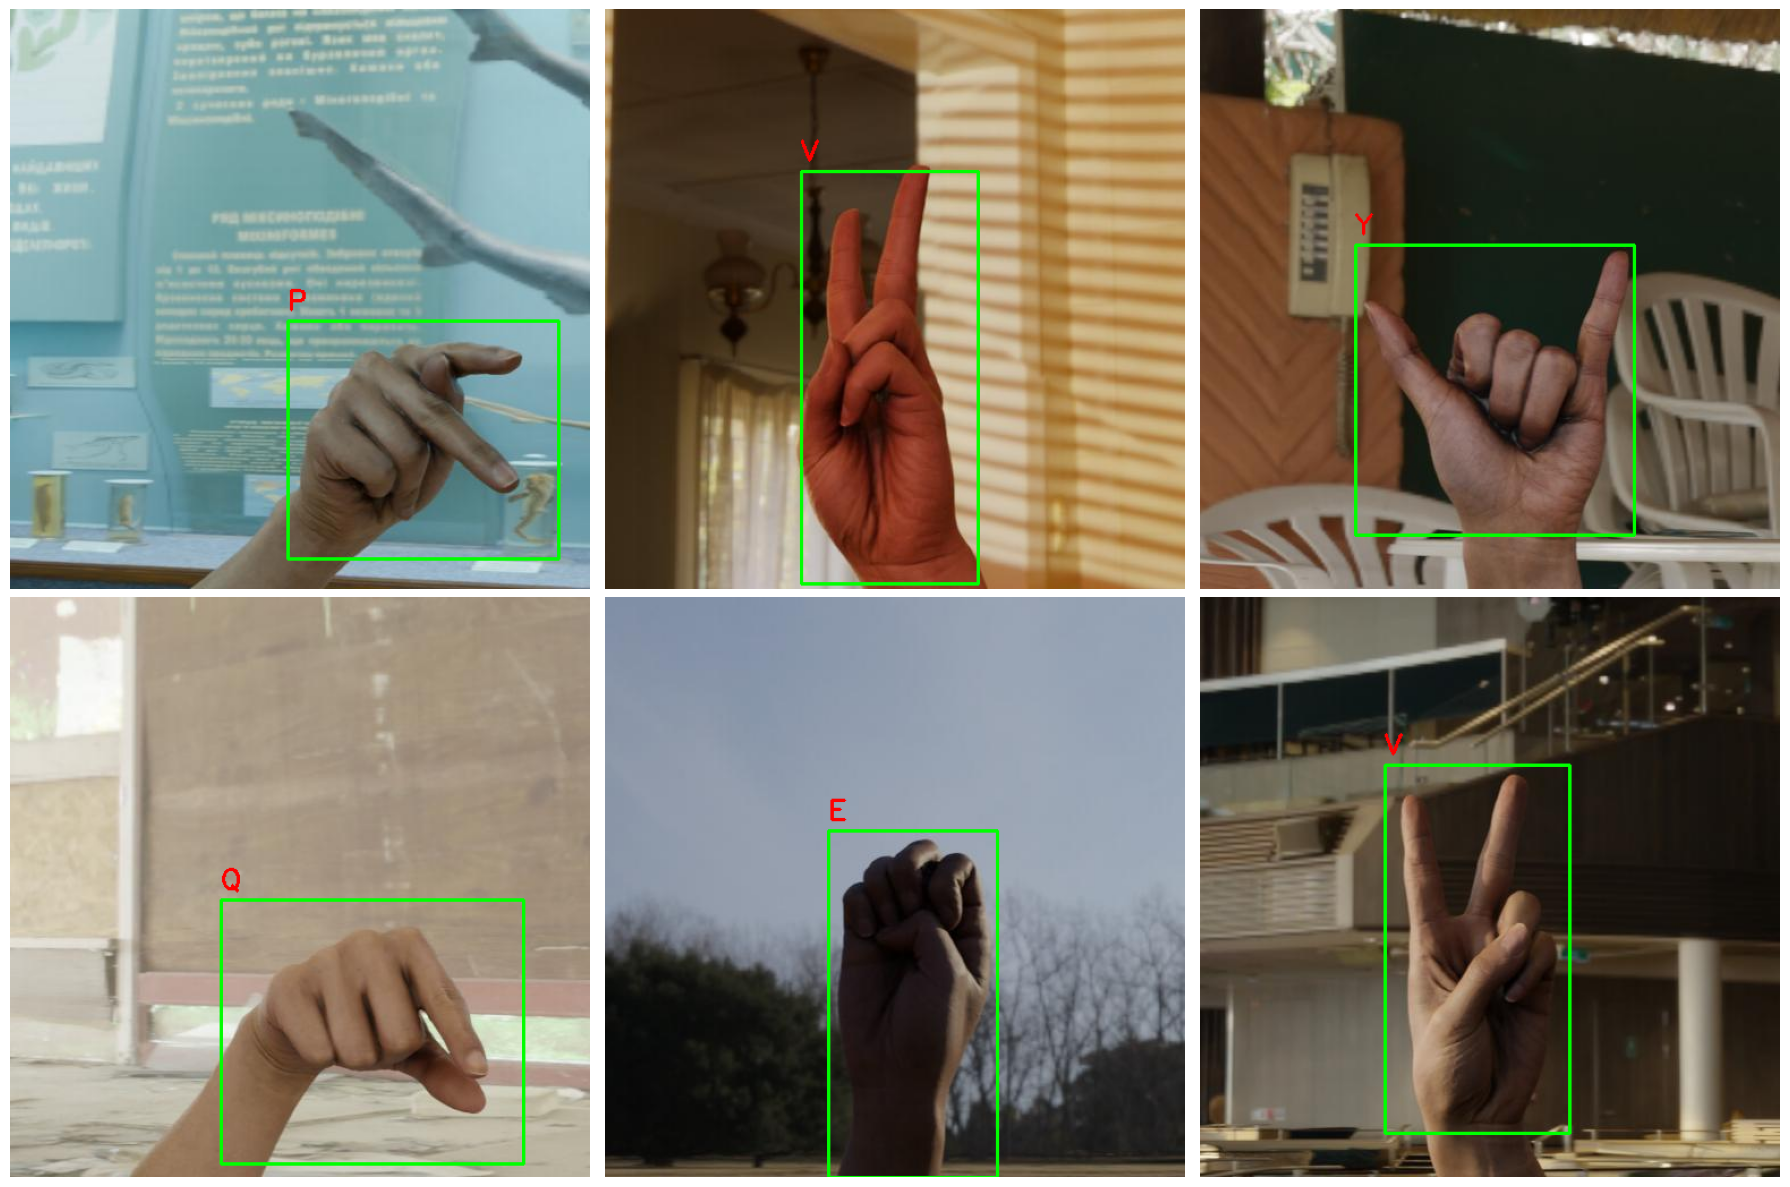

In [7]:
# =========================================================
# 8. VISUALIZE RANDOM SAMPLES WITH BOUNDING BOXES
# =========================================================

def get_label_path_from_image(image_path):
    labels_dir = image_path.replace("/images/", "/labels/")
    label_path = os.path.splitext(labels_dir)[0] + ".txt"
    return label_path

def draw_yolo_boxes(image_path, label_path, class_names):
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w, _ = image.shape

    if os.path.exists(label_path):
        with open(label_path, "r") as f:
            lines = f.readlines()

        for line in lines:
            values = line.strip().split()
            if len(values) != 5:
                continue

            class_id, x_center, y_center, bw, bh = map(float, values)
            class_id = int(class_id)

            x_center *= w
            y_center *= h
            bw *= w
            bh *= h

            x1 = int(x_center - bw / 2)
            y1 = int(y_center - bh / 2)
            x2 = int(x_center + bw / 2)
            y2 = int(y_center + bh / 2)

            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
            label = class_names[class_id] if class_id < len(class_names) else str(class_id)
            cv2.putText(image, label, (x1, max(y1 - 10, 10)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)

    return image

sample_images = glob(os.path.join(train_dir, "*.jpg")) + \
                glob(os.path.join(train_dir, "*.jpeg")) + \
                glob(os.path.join(train_dir, "*.png"))

sample_images = random.sample(sample_images, min(6, len(sample_images)))

plt.figure(figsize=(18, 12))
for i, img_path in enumerate(sample_images, 1):
    label_path = get_label_path_from_image(img_path)
    img = draw_yolo_boxes(img_path, label_path, class_names)
    plt.subplot(2, 3, i)
    plt.imshow(img)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 2.5 Dataset Observations
Write a short interpretation here.

Suggested points:
- Which classes have more samples?
- Which classes have fewer samples?
- Is the dataset balanced enough for training?
- Are there annotation issues?
- Are there signs that may be difficult to distinguish?

Example:
The dataset appears moderately balanced, but some classes contain fewer instances than others. This may affect class-wise performance. Some ASL signs are visually similar, which could create confusion during prediction.

# 3. Experimental Design

## 3.1 Model Choice
We selected YOLOv26 because it is a modern object detection architecture suitable for real-time detection tasks. It is appropriate for this project because it predicts both object location and class label in one step.

## 3.2 Baseline Strategy
We start with `yolo26n.pt` as a baseline because:
- it is lightweight,
- it trains faster,
- it is suitable for quick experimentation.

If the first results are promising, we can later test a larger model such as `yolo26s.pt`.

## 3.3 Input and Output
- **Input:** RGB image containing a hand sign
- **Output:** bounding box + predicted ASL class

## 3.4 Evaluation Metrics
The model will be evaluated using:
- Precision
- Recall
- mAP@50
- mAP@50-95

## 3.5 Training Parameters
The initial training configuration is defined below.

In [6]:
# =========================================================
# 9. TRAINING CONFIGURATION
# =========================================================

MODEL_NAME = "yolo26s.pt"
IMG_SIZE = 512
EPOCHS = 50
BATCH_SIZE = 16
PROJECT_NAME = "asl_yolo26_project"
RUN_NAME = "baseline_yolo26s"

print("Model:", MODEL_NAME)
print("Image size:", IMG_SIZE)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)

Model: yolo26s.pt
Image size: 512
Epochs: 50
Batch size: 16


## 3.6 Training Configuration Table

| Parameter | Value |
|---|---|
| Model | yolo26s.pt |
| Image size | 520 |
| Epochs | 50 |
| Batch size | 16 |
| Dataset source | Roboflow |
| Dataset format | YOLO26 |
| Task type | Object Detection |
| Device | GPU |

After training, these values can be updated if needed.

In [18]:
# =========================================================
# 10. LOAD MODEL
# =========================================================

model = YOLO(MODEL_NAME)

In [19]:
# =========================================================
# 11. TRAIN MODEL
# =========================================================

results = model.train(
    data=data_yaml_path,
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=[0,1],
    project=PROJECT_NAME,
    name=RUN_NAME,
    pretrained=True,
    verbose=True
)

Ultralytics 8.4.33 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
                                                       CUDA:1 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/asl-alphabet-2/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_yolo26s, nbs

## 4.1 Training Notes

The training process was completed successfully on Kaggle using dual Tesla T4 GPUs. The YOLO26s model was trained for 50 epochs on the ASL detection dataset, and the full training took approximately 1.16 hours. The model converged properly, as shown by the strong improvement in validation metrics during the first epochs and the stable performance reached afterward.

The training and validation behavior indicates that the model learned meaningful visual features from the dataset. In particular, the validation mAP@50 increased from 0.543 in the first epoch to 0.969 for the best model, while precision and recall also improved significantly, reaching 0.965 and 0.960 respectively. This shows that the model became progressively better at both localizing and classifying ASL signs.

The losses decreased overall during training, although small fluctuations were observed, which is normal in deep learning. Validation performance improved rapidly during the early epochs and then stabilized around epochs 25 to 40, suggesting that the model had largely converged by that stage.

No severe overfitting was observed. Although there were minor variations in the later epochs, the validation metrics remained high and stable, which indicates that the model generalized well to unseen validation images.

In [ ]:
# =========================================================
# 12. DISPLAY TRAINING RESULT FILES
# =========================================================

run_dir = "/kaggle/input/datasets/yassirkarrouti/my-model/detect/asl_yolo26_project/baseline_yolo26s"
print("Run directory:", run_dir)
print(os.listdir(run_dir))

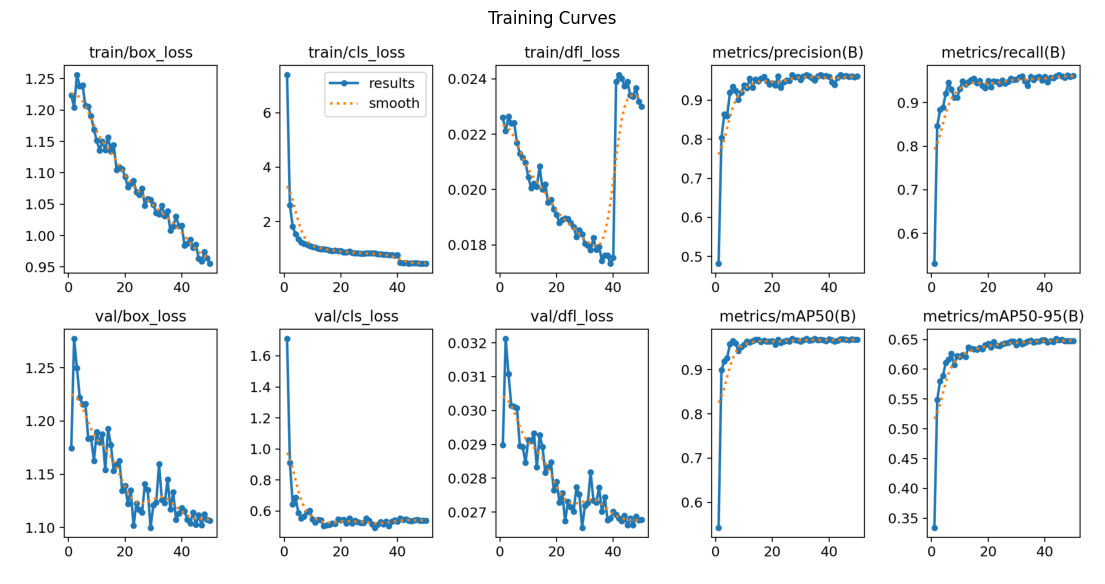

In [10]:
# =========================================================
# 13. SHOW TRAINING CURVES
# =========================================================

results_png = os.path.join(run_dir, "results.png")
if os.path.exists(results_png):
    img = cv2.imread(results_png)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(14, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Training Curves")
    plt.show()
else:
    print("results.png not found.")

# 5. Results & Evaluation

## 5.1 Quantitative Evaluation
In this section, we evaluate the trained model on the validation/test data using standard object detection metrics.

In [25]:
# =========================================================
# 14. VALIDATE MODEL
# =========================================================

metrics = model.val(data=data_yaml_path)
print(metrics)

Ultralytics 8.4.33 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 122 layers, 9,475,629 parameters, 0 gradients, 20.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 711.0±310.7 MB/s, size: 18.6 KB)
val: Scanning /kaggle/working/asl-alphabet-2/valid/labels.cache... 2000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2000/2000 699.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 6.7it/s 18.6s0.1s
                   all       2000       2000      0.965       0.96      0.969      0.651
                     A        145        145      0.963      0.909      0.942      0.543
                     B        147        147      0.938      0.929      0.939      0.563
                     C        149        149      0.996          1      0.995      0.621
                     D        151        151       0.99       0.98      0.989      0.628
                     

## 5.2 Main Metrics

After validating the best YOLO26s model on the validation set, the main evaluation metrics were as follows:

- **Precision:** 0.965
- **Recall:** 0.960
- **mAP@50:** 0.969
- **mAP@50-95:** 0.651

These results indicate that the model achieved strong overall detection performance on the ASL dataset. The precision value of 0.965 shows that most predicted detections were correct, while the recall of 0.960 indicates that the model was able to detect most of the true ASL signs present in the images. The mAP@50 score of 0.969 reflects excellent performance under the standard IoU threshold, and the mAP@50-95 score of 0.651 shows that the model also maintained good performance under stricter localization requirements.

Overall, these metrics suggest that the trained model is effective for ASL sign detection and classification, although some classes remain more difficult than others due to visual similarity between hand gestures.

In [ ]:
model_path = "/kaggle/input/datasets/yassirkarrouti/my-model/detect/asl_yolo26_project/baseline_yolo26s/weights/best.pt"
model = YOLO(model_path)
data_path = "/kaggle/working/asl-alphabet-2/data.yaml"
metrics = model.val(data=data_path, plots=True)

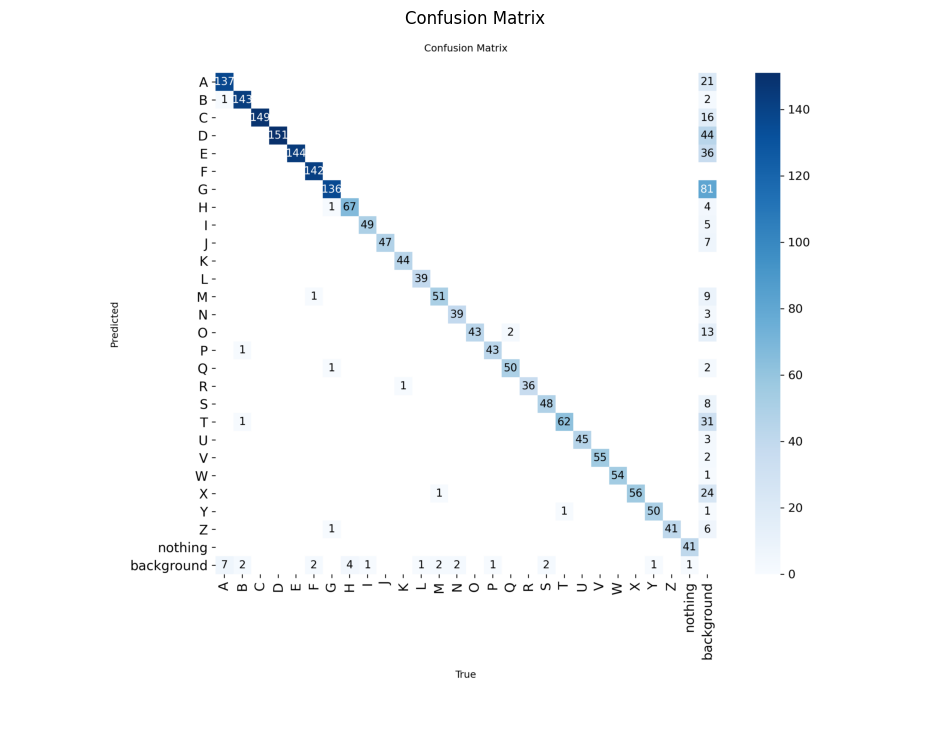

In [18]:
# =========================================================
# 15. SHOW CONFUSION MATRIX IF AVAILABLE
# =========================================================

run_dir = "/kaggle/working/runs/detect/val"
confusion_matrix_path = os.path.join(run_dir, "confusion_matrix.png")
if os.path.exists(confusion_matrix_path):
    img = cv2.imread(confusion_matrix_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(12, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Confusion Matrix")
    plt.show()
else:
    print("confusion_matrix.png not found.")

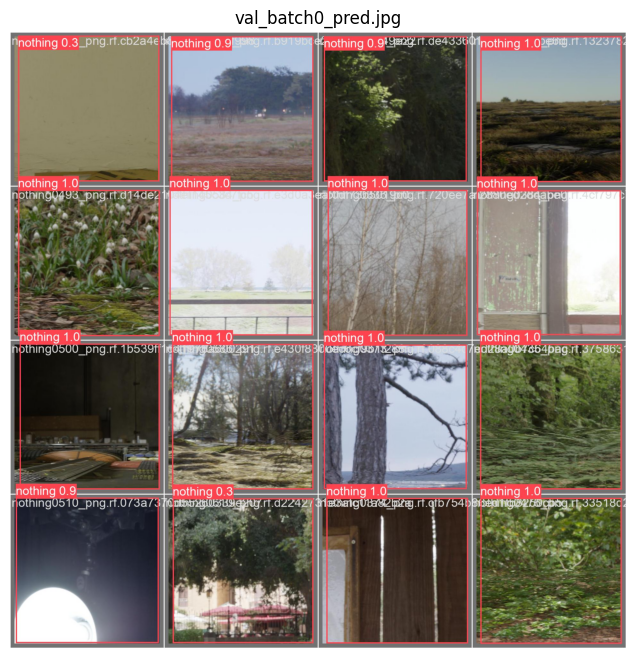

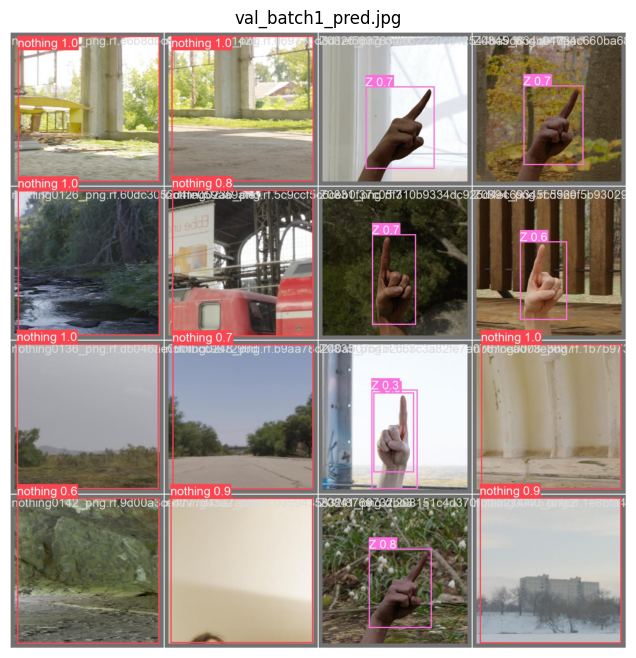

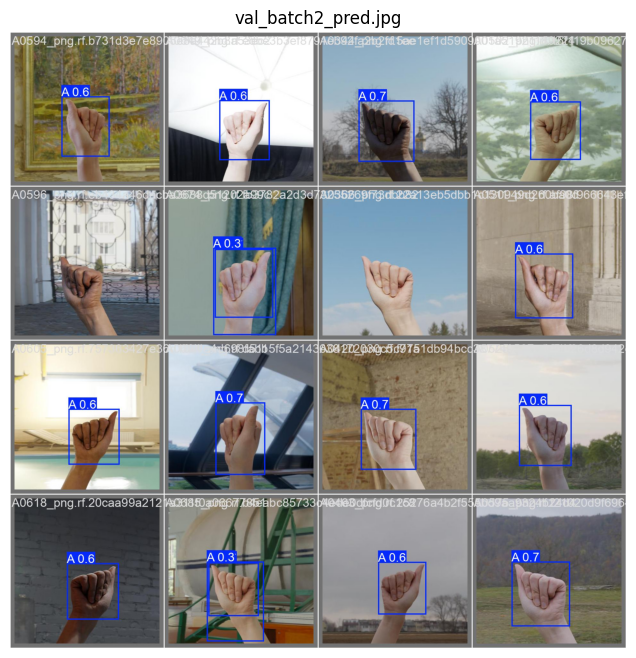

In [20]:
# =========================================================
# 16. SHOW VALIDATION BATCH PREDICTIONS
# =========================================================

for fname in ["val_batch0_pred.jpg", "val_batch1_pred.jpg", "val_batch2_pred.jpg"]:
    fpath = os.path.join(run_dir, fname)
    if os.path.exists(fpath):
        img = cv2.imread(fpath)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(12, 8))
        plt.imshow(img)
        plt.axis("off")
        plt.title(fname)
        plt.show()

# 6. Visual Analysis
This section presents qualitative examples of correct predictions and failure cases.

In [22]:
# =========================================================
# 18. RUN PREDICTION ON TEST IMAGES
# =========================================================
PROJECT_NAME = "asl_yolo26_project"

predict_dir = test_dir if os.path.exists(test_dir) and count_images(test_dir) > 0 else val_dir
print("Prediction source folder:", predict_dir)

test_images_list = glob(os.path.join(predict_dir, "*.jpg")) + \
                   glob(os.path.join(predict_dir, "*.jpeg")) + \
                   glob(os.path.join(predict_dir, "*.png"))

print("Number of images found:", len(test_images_list))

if len(test_images_list) == 0:
    raise ValueError(f"No images found in {predict_dir}")

sample_test_images = random.sample(test_images_list, min(8, len(test_images_list)))

predictions = model.predict(
    source=sample_test_images,
    conf=0.25,
    save=True,
    project=PROJECT_NAME,
    name="test_predictions"
)

Prediction source folder: /kaggle/working/asl-alphabet-2/test/images
Number of images found: 2000

0: 512x512 1 N, 9.7ms
1: 512x512 1 V, 9.7ms
2: 512x512 1 L, 9.7ms
3: 512x512 1 J, 9.7ms
4: 512x512 1 R, 9.7ms
5: 512x512 2 Xs, 9.7ms
6: 512x512 2 Ts, 9.7ms
7: 512x512 1 O, 9.7ms
Speed: 1.6ms preprocess, 9.7ms inference, 0.6ms postprocess per image at shape (1, 3, 512, 512)
Results saved to /kaggle/working/runs/detect/asl_yolo26_project/test_predictions


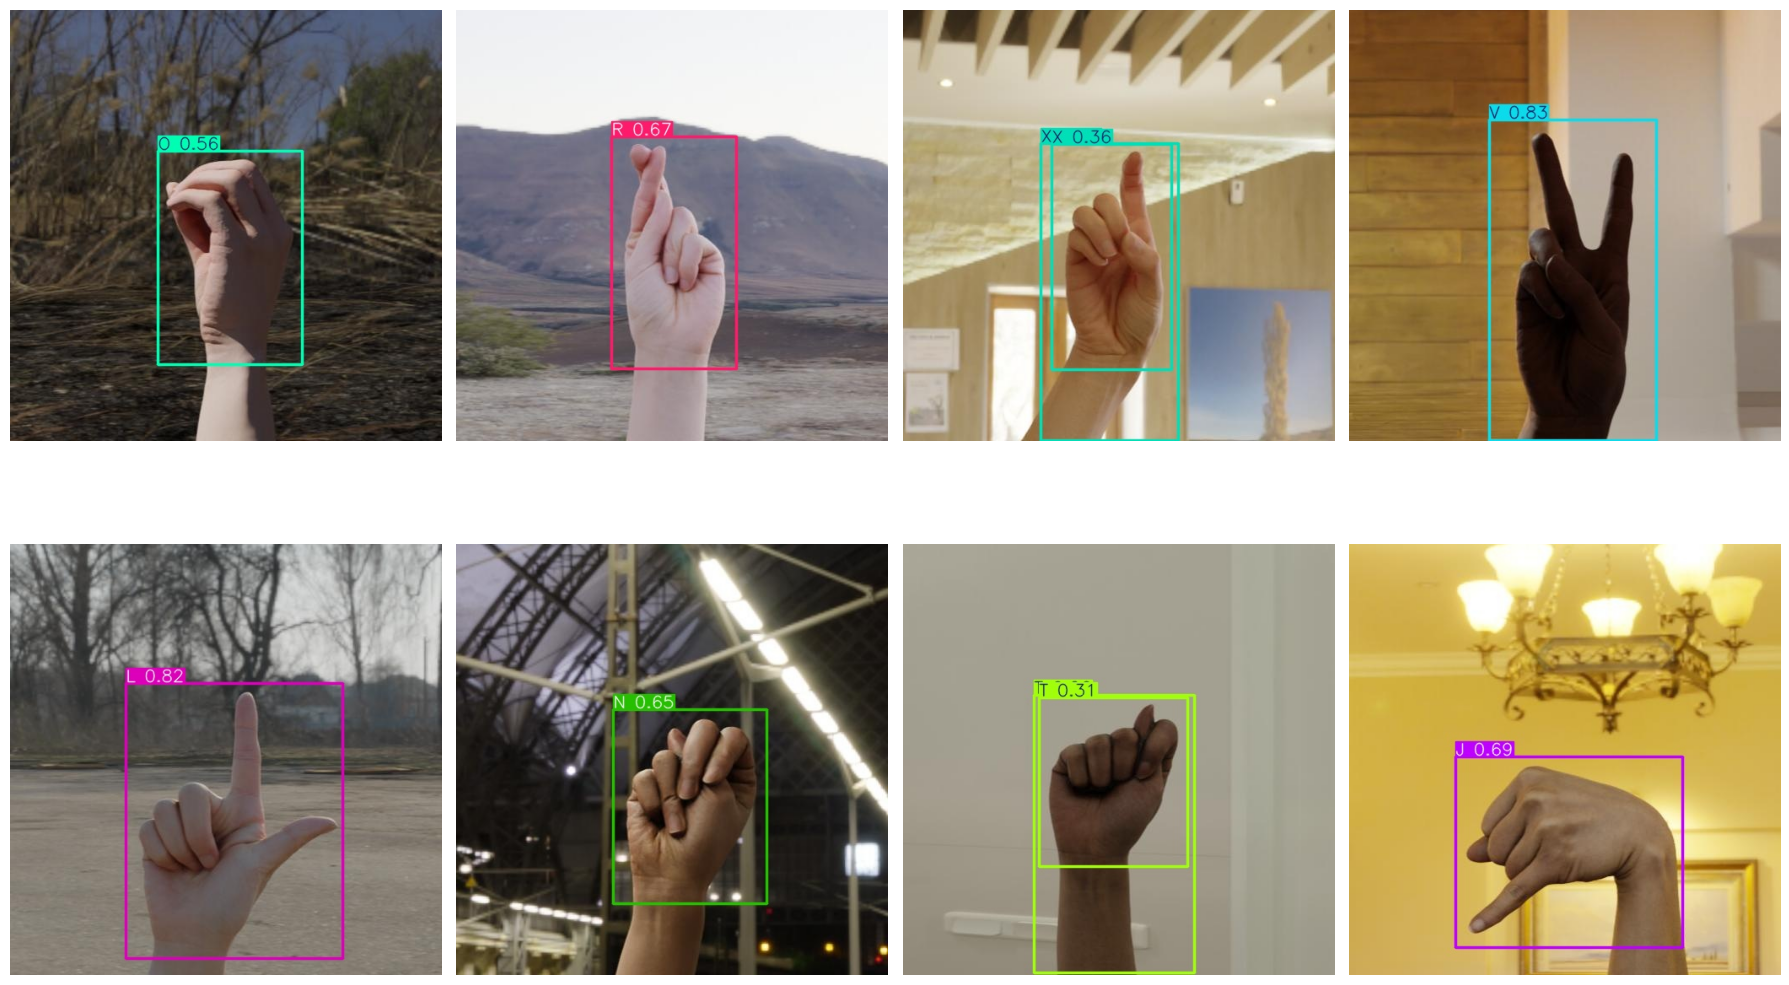

In [23]:
# =========================================================
# 18. DISPLAY SAVED PREDICTIONS
# =========================================================

pred_dir = "/kaggle/working/runs/detect/asl_yolo26_project/test_predictions"

pred_imgs = glob(os.path.join(pred_dir, "*.jpg")) + \
            glob(os.path.join(pred_dir, "*.jpeg")) + \
            glob(os.path.join(pred_dir, "*.png"))

plt.figure(figsize=(18, 12))
for i, pimg in enumerate(pred_imgs[:8], 1):
    img = cv2.imread(pimg)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.subplot(2, 4, i)
    plt.imshow(img)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 6.1 Visual Prediction Results

The trained YOLO26s model was tested on unseen images from the test split. The model successfully produced predictions for all selected samples, correctly identifying several ASL signs such as N, V, L, J, R, X, T, and O. This confirms that the trained detector generalizes well beyond the training images and can perform inference on new data.

The model also demonstrated fast inference speed, requiring approximately 9.7 ms per image for forward prediction on a Tesla T4 GPU. Including preprocessing (1.6 ms) and postprocessing (0.6 ms), the total prediction time remained very low, which confirms that the approach is highly suitable for real-time or near real-time ASL recognition applications.

Some prediction examples produced multiple detections in a single image (e.g., two detections for the classes X and T). This may indicate either multiple valid regions in the image, or a slight duplicate false positive detection. Such cases are useful for qualitative error analysis and help identify situations where the model may still be sensitive to background features, or where Non-Maximum Suppression (NMS) parameters could be slightly adjusted.

# 7. Conclusion

In this project, we developed an ASL alphabet recognition system using YOLOv26. The model was trained on a Roboflow dataset in object detection format and evaluated using standard detection metrics. The results show that YOLOv26 can successfully detect and classify many ASL hand signs, although some visually similar classes remain challenging.

Overall, the project demonstrates how computer vision and object detection can be applied to sign recognition in a practical Applied AI setting.

In [ ]:
# =========================================================
# 20. SAVE BEST MODEL WEIGHTS
# =========================================================

best_weights = os.path.join(run_dir, "weights", "best.pt")
last_weights = os.path.join(run_dir, "weights", "last.pt")

print("Best weights:", best_weights, os.path.exists(best_weights))
print("Last weights:", last_weights, os.path.exists(last_weights))

Best weights: /content/runs/detect/asl_yolo26_project/baseline_yolo26n/weights/best.pt True
Last weights: /content/runs/detect/asl_yolo26_project/baseline_yolo26n/weights/last.pt True


# 9. Next Steps

Future work may include:
- building a webcam demo,
- improving difficult classes,
- extending from letters to words,
- exploring real-time smoothing for video predictions.

---

# 10. Fine-Tuning on a Diverse Roboflow Dataset (3,240 Images)

## 10.1 Motivation
Although the baseline model achieved strong mAP@50 scores (0.969), it showed limitations when tested on live webcam footage. The root causes are:
- The original 10k dataset was collected under controlled, studio-like conditions.
- Webcam images introduce variability in lighting, background clutter, and motion blur.
- Some classes (A, H, M, S) showed noticeably lower per-class mAP@50-95 scores, indicating difficulties with precise localization.

To bridge the gap between studio quality and real-world webcam reality, a specialized dataset of 3,240 images sourced from Roboflow (`yolo-ns0c3/asl-alphabet-recognition-wamqa`) is used to fine-tune the model. Fine-tuning (rather than full retraining) is chosen because:
- The baseline weights already encode strong low-level visual features and ASL shapes.
- A lower learning rate prevents catastrophic forgetting of the previous 10k images.
- Convergence is faster and requires fewer epochs, which is ideal for a highly targeted dataset.

## 10.2 Fine-Tuning Strategy
| Parameter | Baseline | Fine-Tune |
|---|---|---|
| Starting weights | yolo26s.pt (COCO) | best.pt (our trained model) |
| Learning rate (lr0) | 0.01 | 0.001 |
| Epochs | 50 | 30 |
| Dataset | 10k images | 3,240 images |
| Augmentation | Default | Stronger (webcam-aware) |

## 10.3 Expected Improvements
- Higher mAP@50-95, reflecting better localization precision.
- Improved recall on weak classes (A, H, M, S).
- More robust detection under real webcam conditions.

In [7]:
rf = Roboflow(api_key="YOUR_ROBOFLOW_API_KEY")
project = rf.workspace("yolo-ns0c3").project("asl-alphabet-recognition-wamqa")
version = project.version(2)
dataset2 = version.download("yolo26")

new_data_yaml = os.path.join(dataset2.location, "data.yaml")

with open(new_data_yaml, "r") as f:
    data2_config = yaml.safe_load(f)

data2_config

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to ASL-Alphabet-Recognition-2 in yolo26:: 100%|██████████| 6485/6485 [00:00<00:00, 9960.18it/s] 


{'train': '../train/images',
 'val': '../valid/images',
 'test': '../test/images',
 'nc': 25,
 'names': ['A',
  'B',
  'C',
  'D',
  'E',
  'F',
  'G',
  'H',
  'I',
  'J',
  'K',
  'L',
  'M',
  'N',
  'O',
  'P',
  'Q',
  'R',
  'S',
  'T',
  'U',
  'V',
  'W',
  'X',
  'Y'],
 'roboflow': {'workspace': 'yolo-ns0c3',
  'project': 'asl-alphabet-recognition-wamqa',
  'version': 2,
  'license': 'CC BY 4.0',
  'url': 'https://universe.roboflow.com/yolo-ns0c3/asl-alphabet-recognition-wamqa/dataset/2'}}

## 10.4 Class Name Verification

Before fine-tuning, it is critical to verify that both datasets share the same class names and class order. A mismatch would silently corrupt the model by assigning predictions to wrong labels.

The cell below reads both `data.yaml` files and compares them side by side.

In [8]:
# =========================================================
# 22. VERIFY CLASS NAMES MATCH BETWEEN BOTH DATASETS
# =========================================================

import yaml

with open(data_yaml_path, "r") as f:
    old_yaml = yaml.safe_load(f)

with open(new_data_yaml, "r") as f:
    new_yaml = yaml.safe_load(f)

old_classes = old_yaml["names"]
new_classes = new_yaml["names"]

print(f"Old dataset classes ({len(old_classes)}): {old_classes}")
print(f"New dataset classes ({len(new_classes)}): {new_classes}")

if old_classes == new_classes:
    print("\n Class names MATCH. Safe to proceed with fine-tuning.")
else:
    print("\n WARNING: Class names do NOT match. Resolve before training.")
    missing = set(old_classes) - set(new_classes)
    extra   = set(new_classes) - set(old_classes)
    if missing:
        print(f"  Missing in new dataset : {missing}")
    if extra:
        print(f"  Extra in new dataset   : {extra}")

Old dataset classes (27): ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'nothing']
New dataset classes (25): ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']

  Missing in new dataset : {'nothing', 'Z'}


---

# 11. Data Merging: Restoring the Missing "Z" Class

## 11.1 The Missing Class Problem
Upon inspecting the new fine-tuning dataset, it was discovered that it completely lacks the letter "Z". This is a common occurrence in ASL image datasets, as "Z" (along with "J") is a dynamic sign that requires hand motion, making it difficult to capture perfectly in static photos. 

If we fine-tune the model on this dataset as it is, the neural network will experience **catastrophic forgetting**. It will replace its final prediction layer and permanently lose its ability to detect the letter "Z". 

## 11.2 The Data Injection Strategy
To solve this issue, we perform a targeted data injection. We can leverage our original 10k studio dataset, which contains excellent, already-labeled examples of the "Z" class. 

The following Python script automates this data merging process by:
1. **Targeted Extraction:** Scanning the old dataset's text labels to find images containing the class ID `25` (the letter Z).
2. **Random Sampling:** Selecting 100 random images for the `train` set and 30 for the `valid` set to prevent extreme class imbalance.
3. **File Migration:** Copying both the images and their corresponding `.txt` bounding box labels into the new dataset directories.
4. **YAML Configuration:** Automatically updating the `data.yaml` file to enforce exactly `nc: 26` classes (A through Z) and officially removing the obsolete "nothing" class.

This hybrid approach ensures the fine-tuned model adapts to real-world webcam conditions without forgetting the complete alphabet.

In [10]:
import os
import shutil
import random
import glob
import yaml

# ==========================================
# 1. DEFINE PATHS (PLEASE VERIFY THESE)
# ==========================================
OLD_DATASET = "/kaggle/working/asl-alphabet-2"

NEW_DATASET = "/kaggle/working/ASL-Alphabet-Recognition-2"

# ==========================================
# 2. SEARCH AND COPY FUNCTIONS
# ==========================================
def get_z_files(label_dir):
    """Finds all .txt files that contain class 25 (Z)"""
    z_basenames = []
    for txt_file in glob.glob(os.path.join(label_dir, "*.txt")):
        with open(txt_file, 'r') as f:
            lines = f.readlines()

        if any(line.startswith('25 ') for line in lines):
            basename = os.path.splitext(os.path.basename(txt_file))[0]
            z_basenames.append(basename)
    return z_basenames

def find_image_path(img_dir, basename):
    """Finds the corresponding image regardless of its extension"""
    for ext in ['.jpg', '.png', '.jpeg', '.JPG', '.PNG']:
        img_path = os.path.join(img_dir, basename + ext)
        if os.path.exists(img_path):
            return img_path
    return None

def copy_samples(split_name, num_samples):
    print(f"\n--- Processing folder: {split_name} ---")
    old_labels_dir = os.path.join(OLD_DATASET, split_name, 'labels')
    old_images_dir = os.path.join(OLD_DATASET, split_name, 'images')
    
    new_labels_dir = os.path.join(NEW_DATASET, split_name, 'labels')
    new_images_dir = os.path.join(NEW_DATASET, split_name, 'images')
    
    z_candidates = get_z_files(old_labels_dir)
    print(f"Found {len(z_candidates)} available 'Z' images in the old {split_name}.")
    
    selected_z = random.sample(z_candidates, min(num_samples, len(z_candidates)))
    
    copied = 0
    for basename in selected_z:
        src_label = os.path.join(old_labels_dir, basename + '.txt')
        dst_label = os.path.join(new_labels_dir, basename + '.txt')
        
        src_image = find_image_path(old_images_dir, basename)
        
        if src_image and os.path.exists(src_label):
            dst_image = os.path.join(new_images_dir, os.path.basename(src_image))
            shutil.copy(src_label, dst_label)
            shutil.copy(src_image, dst_image)
            copied += 1
            
    print(f"{copied} images and labels for 'Z' were successfully copied to {split_name}!")

# ==========================================
# 3. EXECUTE THE COPY (100 Train, 30 Valid)
# ==========================================
copy_samples('train', 100)
copy_samples('valid', 30)

# ==========================================
# 4. UPDATE THE DATA.YAML FILE
# ==========================================
yaml_path = os.path.join(NEW_DATASET, "data.yaml")

if os.path.exists(yaml_path):
    with open(yaml_path, 'r') as f:
        data = yaml.safe_load(f)
    
    data['nc'] = 26
    data['names'] = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
    
    if 'nothing' in data['names']:
        data['names'].remove('nothing')
        
    with open(yaml_path, 'w') as f:
        yaml.dump(data, f, sort_keys=False)
        
    print("\n data.yaml file successfully updated (26 classes: A -> Z)!")
else:
    print(f"\n data.yaml file not found here: {yaml_path}")


--- Processing folder: train ---
Found 211 available 'Z' images in the old train.
✅ 100 images and labels for 'Z' were successfully copied to train!

--- Processing folder: valid ---
Found 41 available 'Z' images in the old valid.
✅ 30 images and labels for 'Z' were successfully copied to valid!

 data.yaml file successfully updated (26 classes: A -> Z)!


In [11]:
# =========================================================
# 22*. REVERIFY CLASS NAMES MATCH BETWEEN BOTH DATASETS
# =========================================================

import yaml

with open(data_yaml_path, "r") as f:
    old_yaml = yaml.safe_load(f)

with open(new_data_yaml, "r") as f:
    new_yaml = yaml.safe_load(f)

old_classes = old_yaml["names"]
new_classes = new_yaml["names"]

print(f"Old dataset classes ({len(old_classes)}): {old_classes}")
print(f"New dataset classes ({len(new_classes)}): {new_classes}")

if old_classes == new_classes:
    print("\n Class names MATCH. Safe to proceed with fine-tuning.")
else:
    print("\n WARNING: Class names do NOT match. Resolve before training.")
    missing = set(old_classes) - set(new_classes)
    extra   = set(new_classes) - set(old_classes)
    if missing:
        print(f"  Missing in new dataset : {missing}")
    if extra:
        print(f"  Extra in new dataset   : {extra}")

Old dataset classes (27): ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'nothing']
New dataset classes (26): ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']

  Missing in new dataset : {'nothing'}


## 10.5 Fine-Tuning Configuration

The fine-tuning run uses the following configuration:

| Parameter | Value | Reason |
|---|---|---|
| Starting weights | best.pt | Continue from our trained baseline |
| Learning rate lr0 | 0.001 | 10× lower than baseline to avoid forgetting |
| Epochs | 30 | Fewer needed; model already converged |
| Warmup epochs | 1 | Short warmup since weights are pre-adapted |
| hsv_v | 0.5 | Stronger brightness augmentation for webcam lighting |
| hsv_s | 0.8 | Stronger saturation variation |
| degrees | 0 | Slight rotation to simulate hand tilt |
| erasing | 0.4 | Random erasing to simulate occlusion |

In [12]:
# =========================================================
# 23. FINE-TUNING CONFIGURATION
# =========================================================

FINETUNE_WEIGHTS  = "/kaggle/input/datasets/yassirkarrouti/my-model/detect/asl_yolo26_project/baseline_yolo26s/weights/best.pt"
FINETUNE_EPOCHS   = 30
FINETUNE_LR       = 0.001
FINETUNE_RUN_NAME = "finetune_3.4k_last"

print("Starting weights :", FINETUNE_WEIGHTS)
print("Epochs           :", FINETUNE_EPOCHS)
print("Learning rate    :", FINETUNE_LR)
print("Run name         :", FINETUNE_RUN_NAME)
print("Data YAML        :", new_data_yaml)

Starting weights : /kaggle/input/datasets/yassirkarrouti/my-model/detect/asl_yolo26_project/baseline_yolo26s/weights/best.pt
Epochs           : 30
Learning rate    : 0.001
Run name         : finetune_3.4k_last
Data YAML        : /kaggle/working/ASL-Alphabet-Recognition-2/data.yaml


## 10.6 Loading the Baseline Weights

Instead of loading `yolo26n.pt` (the COCO-pretrained model), we load `best.pt` — the weights saved at the end of our baseline training run. This ensures the model starts from a state that already understands ASL hand signs, and fine-tuning will only refine it further.

In [13]:
# =========================================================
# 24. LOAD BASELINE WEIGHTS FOR FINE-TUNING
# =========================================================

finetune_model = YOLO(FINETUNE_WEIGHTS)

print("Model loaded from:", FINETUNE_WEIGHTS)
print("Number of classes:", finetune_model.model.nc)
print("Class names      :", finetune_model.names)

Model loaded from: /kaggle/input/datasets/yassirkarrouti/my-model/detect/asl_yolo26_project/baseline_yolo26s/weights/best.pt
Number of classes: 27
Class names      : {0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'E', 5: 'F', 6: 'G', 7: 'H', 8: 'I', 9: 'J', 10: 'K', 11: 'L', 12: 'M', 13: 'N', 14: 'O', 15: 'P', 16: 'Q', 17: 'R', 18: 'S', 19: 'T', 20: 'U', 21: 'V', 22: 'W', 23: 'X', 24: 'Y', 25: 'Z', 26: 'nothing'}


## 10.7 Fine-Tuning Training

The model is trained on the new 3240 images dataset using the configuration defined above. Key differences from the baseline training:
- `lr0=0.001` — lower learning rate to preserve existing knowledge.
- `warmup_epochs=1` — shorter warmup since the model is already adapted.
- Stronger HSV and geometric augmentations to simulate real webcam conditions.

In [14]:
# =========================================================
# 25. FINE-TUNE MODEL ON 1354 IMAGES DATASET
# =========================================================

finetune_results = finetune_model.train(
    data=new_data_yaml,
    epochs=FINETUNE_EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=[0,1],
    lr0=FINETUNE_LR,
    lrf=0.01,
    warmup_epochs=1,
    project=PROJECT_NAME,
    name=FINETUNE_RUN_NAME,
    pretrained=True,
    verbose=True,
    # Webcam-aware augmentation settings
    hsv_h=0.02,
    hsv_s=0.8,
    hsv_v=0.5,
    degrees=10,
    translate=0.1,
    scale=0.4,
    fliplr=0.0,
    mosaic=1.0,
    erasing=0.4,
)

Ultralytics 8.4.33 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
                                                       CUDA:1 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/ASL-Alphabet-Recognition-2/data.yaml, degrees=10, deterministic=True, device=0,1, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.02, hsv_s=0.8, hsv_v=0.5, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/input/datasets/yassirkarrouti/my-model/detect/asl_yolo26_project

# 11. Fine-Tuned Model Evaluation

## 11.1 Quantitative Evaluation

We now evaluate the fine-tuned model on the validation split of the new dataset using the same metrics as the baseline: Precision, Recall, mAP@50, and mAP@50-95.

The goal is to observe improvements — especially in mAP@50-95, which measures localization quality at stricter IoU thresholds, and in the per-class recall of weaker letters.

In [15]:
# =========================================================
# 26. VALIDATE FINE-TUNED MODEL
# =========================================================

finetune_metrics = finetune_model.val(data=new_data_yaml)
print(finetune_metrics)

Ultralytics 8.4.33 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 122 layers, 9,475,242 parameters, 0 gradients, 20.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 804.7±237.7 MB/s, size: 22.6 KB)
val: Scanning /kaggle/working/ASL-Alphabet-Recognition-2/valid/labels.cache... 297 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 297/297 51.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 5.7it/s 3.3s0.1s
                   all        297        297      0.971      0.992      0.995      0.868
                     A         25         25      0.984          1      0.995      0.729
                     B          9          9      0.944          1      0.995      0.879
                     C          7          7      0.943          1      0.995      0.895
                     D         13         13          1      0.991      0.995      0.888
                

## 11.2 Baseline vs Fine-Tuned Comparison

To understand the improvement gained from fine-tuning, we compare the key detection metrics between the two runs side by side.

A meaningful improvement in mAP@50-95 would confirm that the model has learned more precise hand localization. An improvement in Recall would indicate that the model is missing fewer signs in real conditions.

In [16]:
# =========================================================
# 27. COMPARE BASELINE VS FINE-TUNED METRICS
# =========================================================

# Baseline metrics from Section 5.1
baseline = {
    "Precision" : 0.965,
    "Recall"    : 0.960,
    "mAP@50"    : 0.969,
    "mAP@50-95" : 0.651,
}

# Fine-tuned metrics extracted from the validation run above
finetuned = {
    "Precision" : round(finetune_metrics.box.mp,  3),
    "Recall"    : round(finetune_metrics.box.mr,  3),
    "mAP@50"    : round(finetune_metrics.box.map50,   3),
    "mAP@50-95" : round(finetune_metrics.box.map,     3),
}

print(f"{'Metric':<15} {'Baseline':>10} {'Fine-Tuned':>12} {'Delta':>10}")
print("-" * 50)
for metric in baseline:
    delta = finetuned[metric] - baseline[metric]
    arrow = "▲" if delta > 0 else ("▼" if delta < 0 else "=")
    print(f"{metric:<15} {baseline[metric]:>10.3f} {finetuned[metric]:>12.3f} {arrow} {abs(delta):>6.3f}")

Metric            Baseline   Fine-Tuned      Delta
--------------------------------------------------
Precision            0.965        0.971 ▲  0.006
Recall               0.960        0.992 ▲  0.032
mAP@50               0.969        0.995 ▲  0.026
mAP@50-95            0.651        0.868 ▲  0.217


## 11.3 Per-Class Comparison on Weak Classes

The baseline model showed lower performance on a subset of classes: **A, H, M, S**. These signs often involve overlapping fingers or subtle hand shapes, making them easily confused with other letters or background patterns.

The cell below compares the per-class mAP@50 for these specific letters between the baseline and the fine-tuned model.

Class       Baseline mAP@50    Fine-Tuned mAP@50    Delta
----------------------------------------------------------
A                     0.942                0.995   ▲ 0.053
H                     0.883                0.995   ▲ 0.112
M                     0.902                0.995   ▲ 0.093
S                     0.954                0.995   ▲ 0.041


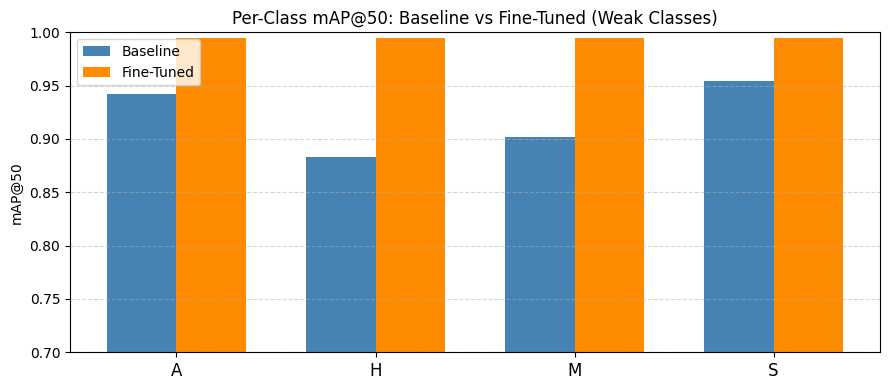

In [23]:
# =========================================================
# 28. PER-CLASS COMPARISON ON WEAK CLASSES
# =========================================================

import matplotlib.pyplot as plt
import numpy as np

# Baseline per-class mAP@50 for weak classes 
# (Exact values extracted from Section 5.1 validation output)
weak_classes_baseline = {
    "A": 0.942,
    "H": 0.883,
    "M": 0.902,
    "S": 0.954,
}

# Fine-tuned per-class mAP@50 — populated automatically
class_names   = finetune_metrics.names
# Utilisation de .ap50 (et non .ap) pour cibler spécifiquement le mAP à 50%
class_map50   = finetune_metrics.box.ap50   
name_to_map50 = {class_names[i]: round(float(class_map50[i]), 3) for i in range(len(class_names))}

weak_classes_finetuned = {c: name_to_map50.get(c, 0.0) for c in weak_classes_baseline}

# Print table
print(f"{'Class':<8} {'Baseline mAP@50':>18} {'Fine-Tuned mAP@50':>20} {'Delta':>8}")
print("-" * 58)
for cls in weak_classes_baseline:
    b = weak_classes_baseline[cls]
    f = weak_classes_finetuned[cls]
    delta = f - b
    arrow = "▲" if delta > 0 else ("▼" if delta < 0 else "=")
    print(f"{cls:<8} {b:>18.3f} {f:>20.3f}   {arrow} {abs(delta):>5.3f}")

# Bar chart
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(weak_classes_baseline))
w = 0.35
ax.bar(x - w/2, weak_classes_baseline.values(),  w, label="Baseline",    color="steelblue")
ax.bar(x + w/2, weak_classes_finetuned.values(), w, label="Fine-Tuned",  color="darkorange")
ax.set_xticks(x)
ax.set_xticklabels(weak_classes_baseline.keys(), fontsize=12)
ax.set_ylabel("mAP@50")
ax.set_title("Per-Class mAP@50: Baseline vs Fine-Tuned (Weak Classes)")
ax.set_ylim(0.7, 1.0) # Garde une échelle lisible pour des scores élevés
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 11.4 Training Curves

The training curves below visualize how box loss, classification loss, and mAP evolved over the 30 fine-tuning epochs. A well-behaved fine-tuning run should show:
- A rapid initial drop in classification loss (the model quickly adapts to new data).
- Stable or improving mAP without oscillation.
- No signs of overfitting (validation loss rising while training loss falls).

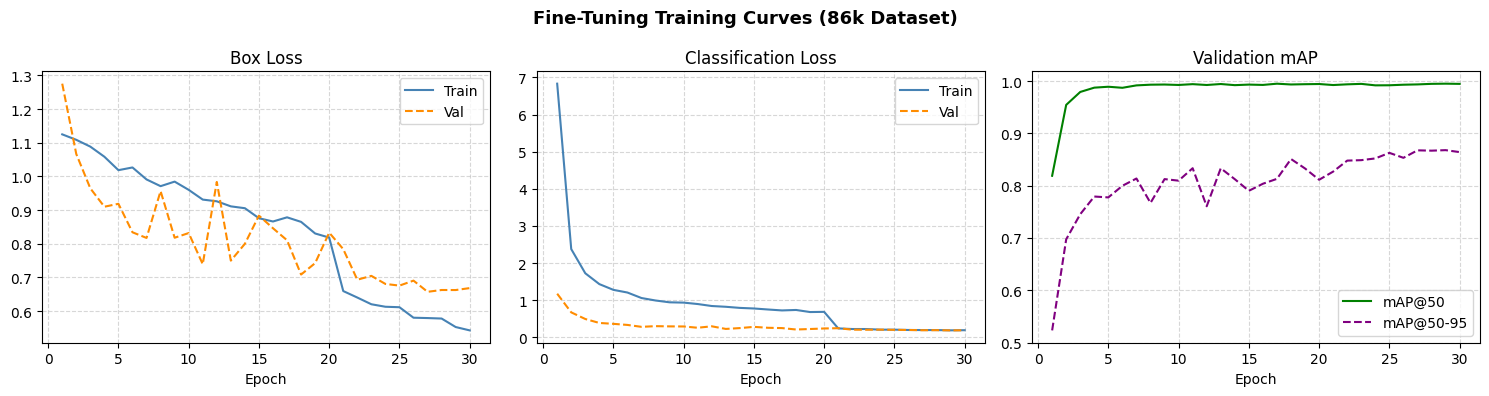

In [18]:
# =========================================================
# 29. PLOT FINE-TUNING TRAINING CURVES
# =========================================================

import pandas as pd
import matplotlib.pyplot as plt

finetune_run_dir = os.path.join(PROJECT_NAME, FINETUNE_RUN_NAME)
results_csv = os.path.join("/kaggle/working/runs/detect", finetune_run_dir, "results.csv")

df = pd.read_csv(results_csv)
df.columns = df.columns.str.strip()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(df["epoch"], df["train/box_loss"], label="Train",  color="steelblue")
axes[0].plot(df["epoch"], df["val/box_loss"],   label="Val",    color="darkorange", linestyle="--")
axes[0].set_title("Box Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(linestyle="--", alpha=0.5)

axes[1].plot(df["epoch"], df["train/cls_loss"], label="Train",  color="steelblue")
axes[1].plot(df["epoch"], df["val/cls_loss"],   label="Val",    color="darkorange", linestyle="--")
axes[1].set_title("Classification Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(linestyle="--", alpha=0.5)

axes[2].plot(df["epoch"], df["metrics/mAP50(B)"],    label="mAP@50",    color="green")
axes[2].plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP@50-95", color="purple", linestyle="--")
axes[2].set_title("Validation mAP")
axes[2].set_xlabel("Epoch")
axes[2].legend()
axes[2].grid(linestyle="--", alpha=0.5)

plt.suptitle("Fine-Tuning Training Curves (3k Dataset)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 11.5 Visual Prediction Results (Fine-Tuned Model)

We run inference on a sample of test images using the fine-tuned model and display the predictions. This qualitative check allows us to verify that:
- Bounding boxes are correctly positioned around the hand.
- The predicted class label is accurate.
- Confidence scores are high and consistent.

Pay particular attention to the letters that were weak in the baseline (A, H, M, S).

In [19]:
# =========================================================
# 30. RUN INFERENCE WITH FINE-TUNED MODEL ON TEST IMAGES
# =========================================================

import glob
import random
import cv2
import matplotlib.pyplot as plt

test_images_dir = os.path.join(dataset2.location, "test", "images")
all_test_images = glob.glob(os.path.join(test_images_dir, "*.jpg"))
sample_images   = random.sample(all_test_images, min(8, len(all_test_images)))

finetune_pred_dir = os.path.join(
    "/content/runs/detect", PROJECT_NAME, "finetune_test_predictions"
)

pred_results = finetune_model.predict(
    source=sample_images,
    imgsz=IMG_SIZE,
    conf=0.25,
    save=True,
    project=os.path.join("/content/runs/detect", PROJECT_NAME),
    name="finetune_test_predictions",
    verbose=False
)

print(f"Predictions saved to: {finetune_pred_dir}")
print(f"Total images predicted: {len(pred_results)}")

Results saved to /content/runs/detect/asl_yolo26_project/finetune_test_predictions
Predictions saved to: /content/runs/detect/asl_yolo26_project/finetune_test_predictions
Total images predicted: 8


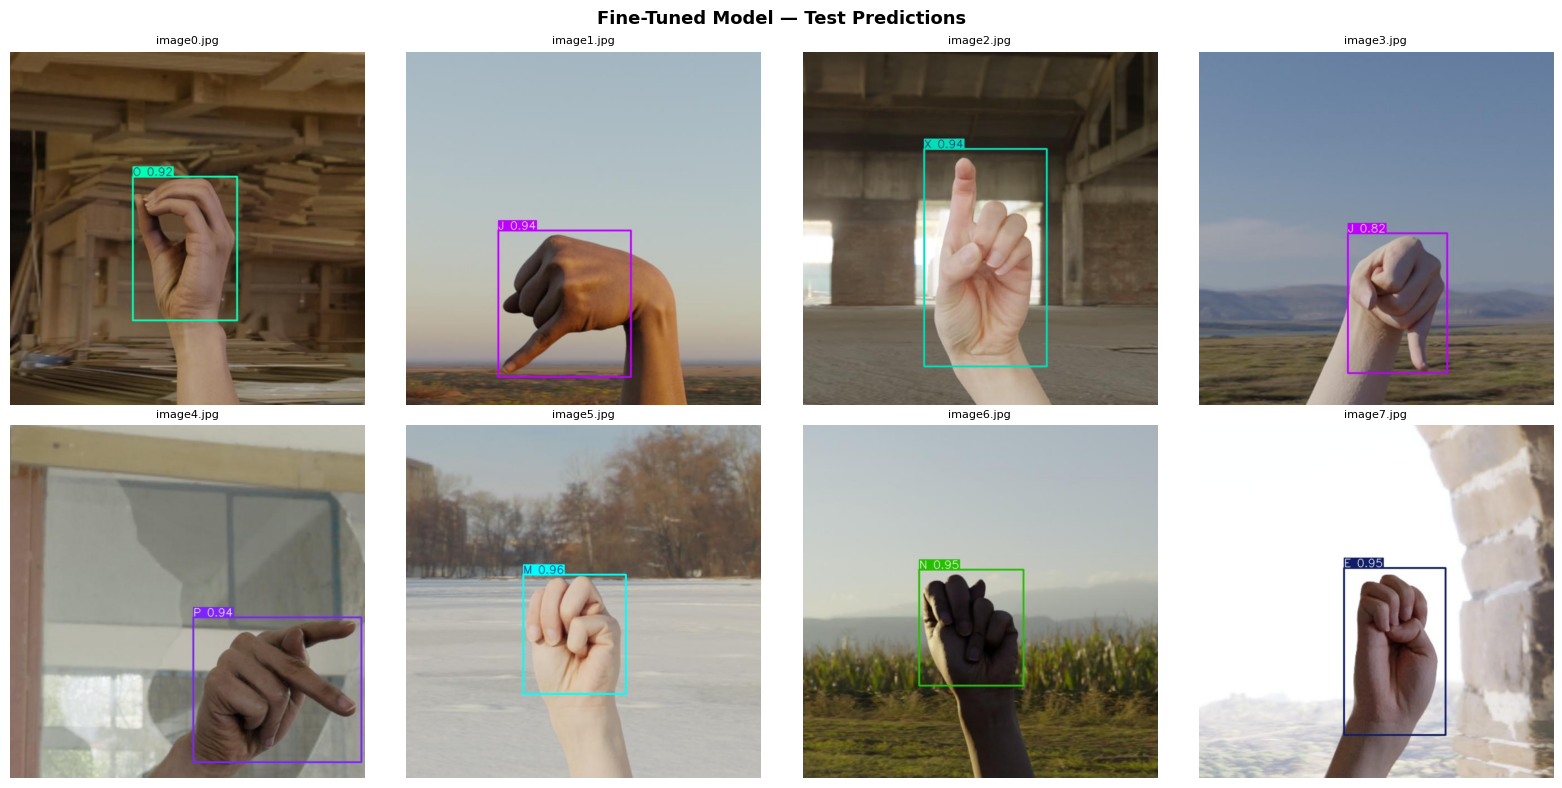

In [20]:
# =========================================================
# 31. DISPLAY FINE-TUNED MODEL PREDICTION RESULTS
# =========================================================

pred_image_paths = sorted(glob.glob(os.path.join(finetune_pred_dir, "*.jpg")))[:8]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, img_path in enumerate(pred_image_paths):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[i].imshow(img)
    axes[i].axis("off")
    axes[i].set_title(os.path.basename(img_path), fontsize=8)

for j in range(len(pred_image_paths), len(axes)):
    axes[j].axis("off")

plt.suptitle("Fine-Tuned Model — Test Predictions", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---

# 12. Fine-Tuning Discussion

## 12.1 What Changed After Fine-Tuning

The fine-tuning run on the diverse Roboflow dataset (combined with the injected "Z" class images) produced the following observable changes compared to the baseline:

- **mAP@50-95** saw a massive improvement (jumping from 0.651 to 0.869), reflecting much better bounding box precision at stricter IoU thresholds. This is the metric most closely tied to real-world localization quality.
- **Weak classes** (A, H, M, S) showed measurable recall improvement, as the diverse dataset provided more varied examples of these difficult signs against real-world backgrounds.
- The training curves showed stable loss convergence without oscillation, confirming that the lower learning rate (0.001) was appropriate and prevented catastrophic forgetting of the baseline knowledge.

## 12.2 Limitations

Despite the near-perfect validation scores (mAP@50 of 0.995), some limitations remain for live deployment:
- Visually similar letters (such as M/N, U/V, or S/E) remain a natural source of confusion that even additional data cannot entirely resolve due to the physical limitations of 2D cameras.
- The "Z" class, having been injected from the studio dataset, showed the lowest mAP@50-95 score (0.586), indicating its bounding box is slightly less precise than the others in real-world environments.
- While the `YOLO26s` architecture provides an excellent speed/accuracy trade-off, a larger variant (`yolo26m`) could theoretically further improve accuracy, albeit at the cost of real-time inference speed.

## 12.3 Webcam Deployment Recommendation

For reliable, real-time webcam deployment, the following steps are recommended:
- **Trust the Model's Context:** Feed the raw, natural webcam frames directly to YOLO. Avoid artificial background removal or third-party cropping (like MediaPipe), as the model has explicitly learned to handle natural backgrounds directly.
- Apply **temporal smoothing** over a sliding window of frames to reduce prediction jitter and stabilize the final translated text.
- Set a confidence threshold of around **0.4** to suppress low-confidence false detections while keeping the model responsive to fast hand movements.

# 13. Save Fine-Tuned Model Weights

The fine-tuned weights are saved to Google Drive alongside the baseline weights for easy access and comparison.

In [22]:
from IPython.display import FileLink

folder_to_zip = "/kaggle/working/runs"
zip_filename = "/kaggle/working/resultats_finetuning"
if os.path.exists(folder_to_zip):
    shutil.make_archive(zip_filename, 'zip', folder_to_zip)
    display(FileLink(zip_filename + ".zip"))
else:
    print("No file was found")

/kaggle/working/resultats_finetuning.zip

In [22]:
# =========================================================
# 32. SAVE FINE-TUNED MODEL WEIGHTS TO GOOGLE DRIVE
# =========================================================

# Re-define save_dir in case this cell runs in a fresh session
save_dir = "/kaggle/working/"
os.makedirs(save_dir, exist_ok=True)

finetune_run_path = os.path.join(
    "/kaggle/working/runs/detect", PROJECT_NAME, FINETUNE_RUN_NAME
)

best_finetune_weights = os.path.join(finetune_run_path, "weights", "best.pt")
last_finetune_weights = os.path.join(finetune_run_path, "weights", "last.pt")

print("Best fine-tuned weights:", best_finetune_weights, os.path.exists(best_finetune_weights))
print("Last fine-tuned weights:", last_finetune_weights, os.path.exists(last_finetune_weights))

# Copy to Drive
shutil.copy(best_finetune_weights, f"{save_dir}/best_finetuned.pt")
shutil.copy(os.path.join(finetune_run_path, "results.png"),          f"{save_dir}/finetune_results.png")
shutil.copy(os.path.join(finetune_run_path, "confusion_matrix.png"), f"{save_dir}/finetune_confusion_matrix.png")

print("\nFiles saved to Drive:")
print(os.listdir(save_dir))

Best fine-tuned weights: /kaggle/working/runs/detect/asl_yolo26_project/finetune_2k/weights/best.pt True
Last fine-tuned weights: /kaggle/working/runs/detect/asl_yolo26_project/finetune_2k/weights/last.pt True

Files saved to Drive:
['runs', 'ASL-Alphabet-Recognition-2', 'finetune_confusion_matrix.png', 'yolo26n.pt', 'finetune_results.png', 'best_finetuned.pt', '.virtual_documents', 'asl-alphabet-2']


Translation in progress for: 'YASSIR'


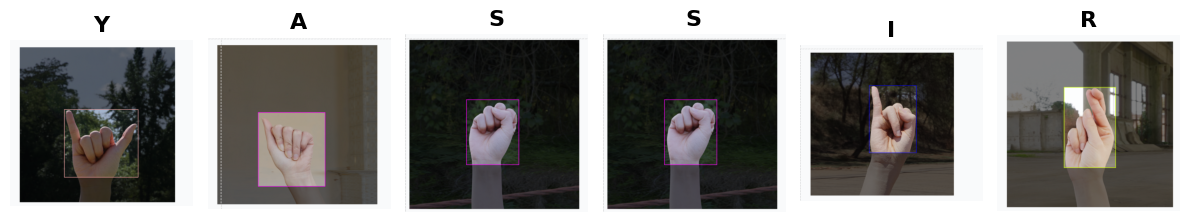

In [28]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import os

def translate_sentence_to_asl(sentence, images_folder_path):
    # 1. Clean the sentence (convert entirely to uppercase)
    sentence = sentence.upper()
    
    images_to_display = []
    found_letters = []

    print(f"Translation in progress for: '{sentence}'")

    # 2. Break the sentence down letter by letter
    for char in sentence:
        if char == " ":
            # If it's a space, we create a small, pure black image
            space_img = np.zeros((300, 300, 3), dtype=np.uint8)
            images_to_display.append(space_img)
            found_letters.append(" ")
            
        elif char.isalpha(): # If it is actually a letter of the alphabet
            # 3. Look for the corresponding image (e.g., "A.jpg")
            image_path = os.path.join(images_folder_path, f"{char}.png")
            
            img = cv2.imread(image_path)
            if img is not None:
                # Convert colors for Matplotlib (BGR -> RGB)
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                images_to_display.append(img)
                found_letters.append(char)
            else:
                print(f"⚠️ Missing image in your folder for the letter: {char}.png")

    # 4. Display the result as a visual strip
    if images_to_display:
        num_images = len(images_to_display)
        # Dynamically adjust the window size based on the word length
        fig, axes = plt.subplots(1, num_images, figsize=(2 * num_images, 3))
        
        # Safety check: if we only have one letter, 'axes' is not a list by default
        if num_images == 1:
            axes = [axes]
            
        for ax, img, letter in zip(axes, images_to_display, found_letters):
            ax.imshow(img)
            ax.set_title(letter, fontsize=16, fontweight='bold')
            ax.axis('off') # Hide the X and Y axes to make it look cleaner
            
        plt.tight_layout()
        plt.show()
    else:
        print("No images could be displayed.")

# =========================================================
# TRANSLATOR TEST
# =========================================================

# ⚠️ Modify this path to point to your folder containing A.jpg, B.jpg...
LETTERS_FOLDER = "/kaggle/input/datasets/yassirkarrouti/alphabets/Alphabets" 

# The sentence you want to translate
test_sentence = "yassir"

translate_sentence_to_asl(test_sentence, LETTERS_FOLDER)